# 5. Self-Attention and a Tiny GPT

Behind the Secrets of LLMs, crash course part 2

The bigram model from notebook 4 only looked at one previous character and got stuck at a validation loss of about 2.5. In this notebook every position gets to look at all earlier positions through self-attention. We stack that into a Transformer and train a small GPT on Shakespeare.

We go step by step:

1. what the training data of a language model looks like (a context and the next token)
2. averaging over the past, written as a matrix multiplication
3. scaled dot-product self-attention with a causal mask, and why we divide by $\sqrt{d}$
4. multi-head attention, MLP, residual connections and LayerNorm, which together make a Transformer block
5. training TinyGPT, generating text, and looking at its attention maps

Time: about 60 minutes. It runs on a CPU with small settings (about 3 minutes of training). On a Colab GPU it is faster: Runtime > Change runtime type > T4 GPU, and the notebook picks bigger settings by itself.

In [1]:
import math, os, time, urllib.request
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(1337)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", device)

URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
if not os.path.exists("input.txt"):
    urllib.request.urlretrieve(URL, "input.txt")
text = open("input.txt", encoding="utf-8").read()

chars = sorted(set(text)); V = len(chars)
stoi = {c: i for i, c in enumerate(chars)}; itos = {i: c for c, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(itos[i] for i in ids)

data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]
print(f"{len(text):,} characters, vocabulary |V| = {V}")

torch 2.14.1+cu130 | device: cpu
1,115,394 characters, vocabulary |V| = 65


## 1. What does a language model train on?

We cut random windows of `block_size` characters out of the text. The target is the same window moved one character to the right. So one window of length $T$ already holds $T$ training examples:

In [2]:
block_size = 8
x = train_data[:block_size]
y = train_data[1:block_size + 1]
for t in range(block_size):
    print(f"context {decode(x[:t + 1].tolist())!r:>14}  ->  next {decode([y[t].item()])!r}")

context            'F'  ->  next 'i'
context           'Fi'  ->  next 'r'
context          'Fir'  ->  next 's'
context         'Firs'  ->  next 't'
context        'First'  ->  next ' '
context       'First '  ->  next 'C'
context      'First C'  ->  next 'i'
context     'First Ci'  ->  next 't'


In [3]:
def get_batch(split, batch_size, block_size):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - block_size - 1, (batch_size,))
    x = torch.stack([d[i:i + block_size] for i in ix])
    y = torch.stack([d[i + 1:i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)

xb, yb = get_batch("train", 4, 8)
print("inputs  x:", xb.shape, "\n", xb.cpu())
print("targets y:", yb.shape, "\n", yb.cpu())

inputs  x: torch.Size([4, 8]) 
 tensor([[53, 59,  6,  1, 58, 56, 47, 40],
        [49, 43, 43, 54,  1, 47, 58,  1],
        [13, 52, 45, 43, 50, 53,  8,  0],
        [ 1, 39,  1, 46, 53, 59, 57, 43]])
targets y: torch.Size([4, 8]) 
 tensor([[59,  6,  1, 58, 56, 47, 40, 59],
        [43, 43, 54,  1, 47, 58,  1, 58],
        [52, 45, 43, 50, 53,  8,  0, 26],
        [39,  1, 46, 53, 59, 57, 43,  0]])


## 2. Letting tokens talk to each other: averaging the past

The simplest way for token $t$ to use its context is to average the vectors of all tokens up to $t$. It must not see the future, because the future is what it has to predict:

$$\bar{x}_t = \frac{1}{t}\sum_{s \le t} x_s$$

Written with a lower-triangular weight matrix $W$, this is just $\bar{X} = W X$. The same $W$ also comes out of a softmax over a masked score matrix: scores of $-\infty$ in the future turn into a weight of 0.

In [4]:
B, T, C = 1, 5, 2
x = torch.randn(B, T, C)

# version 1: python loop
xbow1 = torch.zeros_like(x)
for t in range(T):
    xbow1[:, t] = x[:, :t + 1].mean(dim=1)

# version 2: matrix multiplication with a row-normalised lower-triangular matrix
W = torch.tril(torch.ones(T, T))
W = W / W.sum(dim=1, keepdim=True)
xbow2 = W @ x

# version 3: softmax over masked scores (all scores 0 here -> uniform weights)
scores = torch.zeros(T, T).masked_fill(torch.tril(torch.ones(T, T)) == 0, float("-inf"))
W3 = F.softmax(scores, dim=-1)
xbow3 = W3 @ x

print(W3)
print("loop == matmul == softmax:", torch.allclose(xbow1, xbow2), torch.allclose(xbow2, xbow3))

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000]])
loop == matmul == softmax: True True


Plain averaging treats every earlier token as equally important. Self-attention lets the weights depend on the data.

## 3. Scaled dot-product self-attention

Every token makes three vectors from its embedding $x$, each with its own learned linear map:

* a **query** $q = xW_Q$: what am I looking for?
* a **key** $k = xW_K$: what do I have to offer?
* a **value** $v = xW_V$: what do I pass on if someone attends to me?

$$\text{Attention}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right)V, \qquad M_{ts} = \begin{cases}0 & s \le t\\ -\infty & s > t\end{cases}$$

The score $q_t \cdot k_s$ is large when what token $t$ is looking for matches what token $s$ has. $M$ is the causal mask.

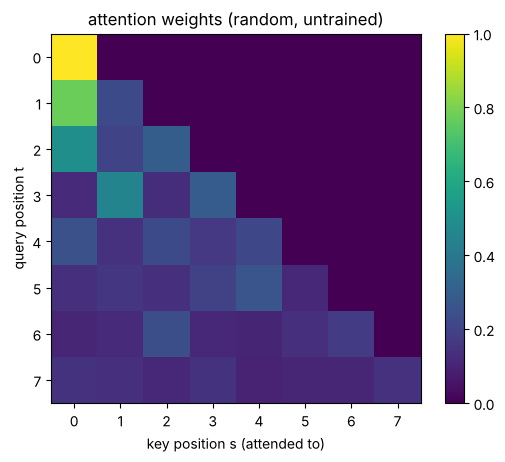

output shape: torch.Size([1, 8, 16])


In [5]:
torch.manual_seed(0)
B, T, C, head_size = 1, 8, 32, 16
x = torch.randn(B, T, C)

key   = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)
value = nn.Linear(C, head_size, bias=False)
k, q, v = key(x), query(x), value(x)                     # (B, T, head_size)

att = q @ k.transpose(-2, -1) / math.sqrt(head_size)     # (B, T, T) similarity scores
att = att.masked_fill(torch.tril(torch.ones(T, T)) == 0, float("-inf"))
att = F.softmax(att, dim=-1)                             # each row sums to 1
out = att @ v                                            # (B, T, head_size)

plt.imshow(att[0].detach(), cmap="viridis")
plt.xlabel("key position s (attended to)"); plt.ylabel("query position t")
plt.title("attention weights (random, untrained)"); plt.colorbar(); plt.show()
print("output shape:", out.shape)

### Why divide by $\sqrt{d_k}$?

If the entries of $q$ and $k$ have mean 0 and variance 1, then $q\cdot k = \sum_{i=1}^{d_k} q_i k_i$ has variance $d_k$. Large scores push the softmax towards a one-hot vector, so every token would only look at one other token and the gradients would vanish. Dividing by $\sqrt{d_k}$ brings the variance back to 1.

In [6]:
d = 64
q, k = torch.randn(1000, d), torch.randn(1000, d)
raw = (q * k).sum(dim=1)
print(f"var(q.k)          = {raw.var():6.2f}   (~ d = {d})")
print(f"var(q.k / sqrt d) = {(raw / math.sqrt(d)).var():6.2f}   (~ 1)")

row = torch.randn(8, d) @ torch.randn(d)                 # 8 scores for one query
print("softmax without scaling:", F.softmax(row, dim=0).numpy().round(3))
print("softmax with scaling   :", F.softmax(row / math.sqrt(d), dim=0).numpy().round(3))

var(q.k)          =  65.40   (~ d = 64)
var(q.k / sqrt d) =   1.02   (~ 1)
softmax without scaling: [0. 0. 1. 0. 0. 0. 0. 0.]
softmax with scaling   : [0.108 0.034 0.549 0.077 0.039 0.036 0.012 0.147]


## 4. From one head to a Transformer block

* **Multi-head attention.** We run $h$ heads with $d_k = d_{model}/h$ side by side. Each head can look for something different, for example the previous vowel or the start of the line. Their outputs are glued together and projected.
* **Feed-forward MLP.** After the tokens have talked to each other, each token thinks on its own: $\text{MLP}(x) = W_2\,\text{GELU}(W_1 x)$.
* **Residual connections and LayerNorm** keep a deep stack trainable:

$$x \leftarrow x + \text{MHA}(\text{LN}(x)), \qquad x \leftarrow x + \text{MLP}(\text{LN}(x))$$

* **Position embeddings.** Attention on its own does not know the order of the tokens, so we add a learned vector for every position.

The whole model is: token embedding plus position embedding, then $N$ blocks, a final LayerNorm, and a linear layer that gives $|\mathcal{V}|$ logits. The loss is the cross-entropy, exactly as in notebook 4.

In [7]:
class Head(nn.Module):
    # one head of causal self-attention
    def __init__(self, n_embd, head_size, block_size, dropout):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)
        self.last_att = None                                  # kept for visualisation

    def forward(self, x):
        B, T, C = x.shape
        k, q, v = self.key(x), self.query(x), self.value(x)
        att = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])
        att = att.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
        att = F.softmax(att, dim=-1)
        self.last_att = att.detach()
        return self.dropout(att) @ v


class MultiHeadAttention(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.heads = nn.ModuleList([Head(n_embd, n_embd // n_head, block_size, dropout) for _ in range(n_head)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)   # concatenate the heads
        return self.dropout(self.proj(out))


class FeedForward(nn.Module):
    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_embd, 4 * n_embd), nn.GELU(),
                                 nn.Linear(4 * n_embd, n_embd), nn.Dropout(dropout))

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(n_embd), nn.LayerNorm(n_embd)
        self.sa = MultiHeadAttention(n_embd, n_head, block_size, dropout)
        self.ffwd = FeedForward(n_embd, dropout)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))      # communicate
        x = x + self.ffwd(self.ln2(x))    # compute
        return x


class TinyGPT(nn.Module):
    def __init__(self, V, block_size, n_embd, n_head, n_layer, dropout):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(V, n_embd)
        self.pos_emb = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head, block_size, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, V)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(T, device=idx.device))
        logits = self.lm_head(self.ln_f(self.blocks(x)))          # (B, T, V)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(B * T, -1), targets.view(B * T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0):
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -self.block_size:])           # never more than block_size
            probs = F.softmax(logits[:, -1, :] / temperature, dim=-1)
            idx = torch.cat([idx, torch.multinomial(probs, 1)], dim=1)
        return idx

### Settings and a quick check

Before training, the model knows nothing, so its loss should be close to $\log|\mathcal{V}| = \log 65 \approx 4.17$, the same as uniform guessing in notebook 4.

In [8]:
if device == "cuda":      # Colab T4 / any GPU: ~2-3 minutes
    cfg = dict(block_size=128, n_embd=192, n_head=6, n_layer=4, dropout=0.1,
               batch_size=64, steps=3000, lr=1e-3, eval_interval=300)
else:                     # CPU: ~3 minutes, smaller model and context
    cfg = dict(block_size=64, n_embd=64, n_head=4, n_layer=3, dropout=0.0,
               batch_size=32, steps=2500, lr=2e-3, eval_interval=250)

model = TinyGPT(V, cfg["block_size"], cfg["n_embd"], cfg["n_head"], cfg["n_layer"], cfg["dropout"]).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f} M parameters")

xb, yb = get_batch("train", cfg["batch_size"], cfg["block_size"])
_, loss = model(xb, yb)
print(f"loss at init {loss.item():.3f}   vs   log|V| = {math.log(V):.3f}")

0.16 M parameters


loss at init 4.371   vs   log|V| = 4.174


## 5. Training, with the same loop as for MNIST

Forward pass, loss, `zero_grad`, `backward`, `step`. Every few hundred steps we also estimate the train and validation loss.

In [9]:
@torch.no_grad()
def estimate_loss(iters=30):
    model.eval()
    out = {}
    for split in ["train", "val"]:
        losses = [model(*get_batch(split, cfg["batch_size"], cfg["block_size"]))[1].item() for _ in range(iters)]
        out[split] = sum(losses) / len(losses)
    model.train()
    return out

opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"])
log = {"step": [], "train": [], "val": []}
t0 = time.time()
for step in range(1, cfg["steps"] + 1):
    xb, yb = get_batch("train", cfg["batch_size"], cfg["block_size"])
    _, loss = model(xb, yb)
    opt.zero_grad(set_to_none=True)
    loss.backward()
    opt.step()
    if step % cfg["eval_interval"] == 0 or step == 1:
        l = estimate_loss()
        log["step"].append(step); log["train"].append(l["train"]); log["val"].append(l["val"])
        print(f"step {step:5d} | train {l['train']:.3f} | val {l['val']:.3f} | {time.time() - t0:5.0f}s")

step     1 | train 4.119 | val 4.121 |     1s


step   250 | train 2.314 | val 2.327 |    11s


step   500 | train 2.057 | val 2.111 |    41s


step   750 | train 1.901 | val 1.986 |    52s


step  1000 | train 1.780 | val 1.898 |    64s


...

step  1500 | train 1.661 | val 1.820 |    84s


step  1750 | train 1.599 | val 1.795 |    95s


step  2000 | train 1.607 | val 1.758 |   106s


step  2250 | train 1.582 | val 1.756 |   117s


step  2500 | train 1.562 | val 1.746 |   127s


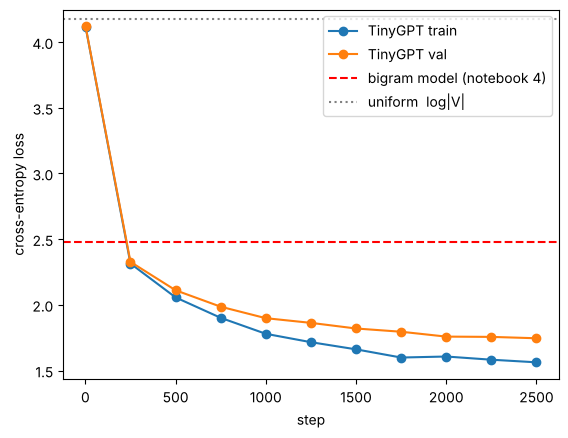

In [10]:
plt.plot(log["step"], log["train"], "o-", label="TinyGPT train")
plt.plot(log["step"], log["val"], "o-", label="TinyGPT val")
plt.axhline(2.48, color="r", ls="--", label="bigram model (notebook 4)")
plt.axhline(math.log(V), color="gray", ls=":", label="uniform  log|V|")
plt.xlabel("step"); plt.ylabel("cross-entropy loss"); plt.legend(); plt.show()

In [11]:
model.eval()
for prompt in ["\n", "ROMEO:\n"]:
    idx = torch.tensor([encode(prompt)], device=device)
    print("=" * 60)
    print(decode(model.generate(idx, 400, temperature=0.8)[0].tolist()))



BUCKINGHAM:
Thou trop'reach a advised to house keep,
In thou confess and all desire, end them lady
The liek wele the done: I have how, was if age;
I will have I though wert as though the many master?

Sritherd:
What it doth the prince, who being to comport
With his him, Good hear? what you see, my man,
The dight is, pitition to the death: but the power as my son the chard,
Should be so, thou disc


ROMEO:
Why, and I see that, I do thy revemal'd thus the preseiveded dive but and I
am thee countronoud it telless people;
And your word, for your seave breep we lord,
With tumple to braw his purike an your honour,
Phonest to corn the for in this all death,
The soffeics over the bord and green
To place,---no long'd which seap, I to Rome
to deather thuman to Ere forgny I the cafford words.

FLORD OF YORK:



Words, line breaks, speaker names and punctuation, all learned from raw characters with nothing but next-token prediction.

## 6. Looking inside: what do the heads attend to?

Each head in the first layer produces a $T \times T$ attention matrix. Every row is a query position, and the columns show where it looks.

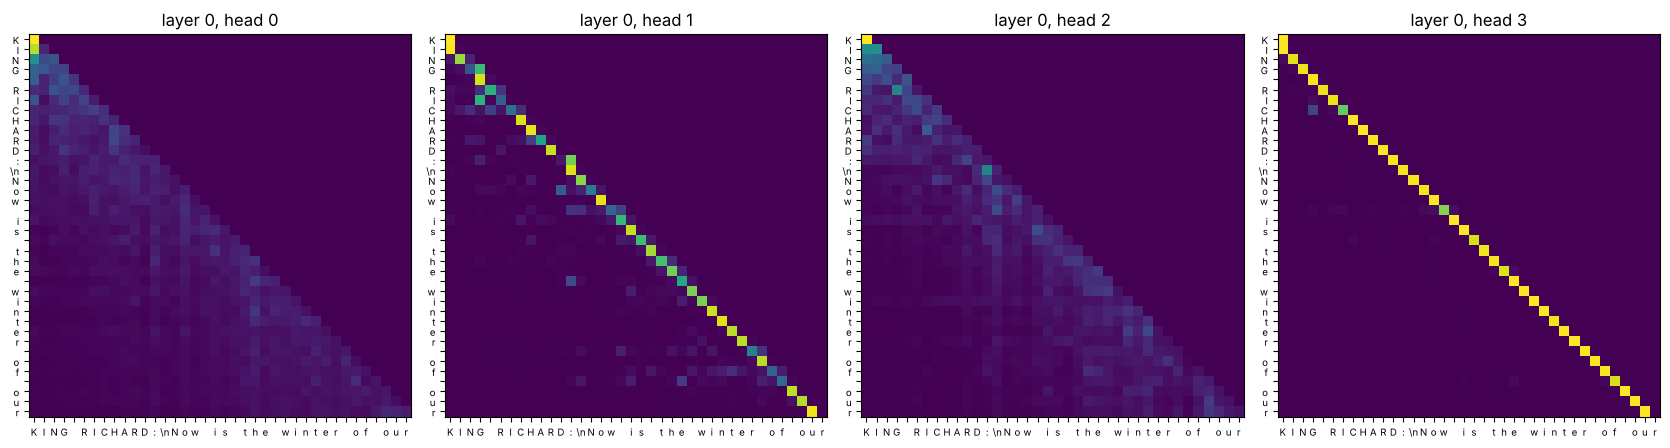

In [12]:
prompt = "KING RICHARD:\nNow is the winter of our"
idx = torch.tensor([encode(prompt)], device=device)
with torch.no_grad():
    model(idx)

layer = 0
heads = model.blocks[layer].sa.heads
fig, axes = plt.subplots(1, len(heads), figsize=(4.2 * len(heads), 4.5))
labels = [c if c != "\n" else "\\n" for c in prompt]
for h, ax in enumerate(axes):
    ax.imshow(heads[h].last_att[0].cpu(), cmap="viridis")
    ax.set_xticks(range(len(prompt))); ax.set_xticklabels(labels, fontsize=7)
    ax.set_yticks(range(len(prompt))); ax.set_yticklabels(labels, fontsize=7)
    ax.set_title(f"layer {layer}, head {h}")
plt.tight_layout(); plt.show()

You will usually see a head that looks at the current or the previous character (a sharp diagonal), and heads that spread their attention over the last few characters or back to the start of the word. Your maps will look a bit different every run. Nobody programmed these patterns. The model learned them because they lower the loss.

---

### Exercises

1. **Remove the mask.** Delete the `masked_fill` line in `Head` and train for 300 steps. The training loss drops a lot. Why is this cheating, and what happens when you generate text?
2. **No positions.** Remove `self.pos_emb(...)` from `forward`. How much worse is the validation loss? Why can't attention tell positions apart by itself?
3. **Bigger.** Double `n_embd` and `n_layer`. Count the parameters, time one step, and compare the final validation loss. This is where the cluster helps, see below.
4. **Context length.** Train with `block_size=16` and with `block_size=128`. What can a model with a short context never learn?
5. **One head or many.** Use `n_head=1` with the same `n_embd`. Compare the loss and the attention maps.

### Running it on the cluster

The same model is in `hpc_lab/04_tinygpt/train_tinygpt.py`. On an A100 or H100 you can train a model ten times bigger in the same time:

```bash
cd hpc_lab/04_tinygpt && mkdir -p logs
sbatch train.sbatch --n-layer 6 --n-head 6 --n-embd 384 --block-size 256
```